# 06 - SVM trên Diabetes prediction dataset

Mục tiêu: dùng mẫu phân tầng 10.000 dòng để tuning SVM, sau đó đánh giá trên test set cùng mẫu. Dữ liệu không phải Pima và target mất cân bằng.

## 1. Load data và EDA ngắn

Shape ban đầu: (100000, 9)
Số dòng trùng lặp: 3854
Missing values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64
Phân bố target:
diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64


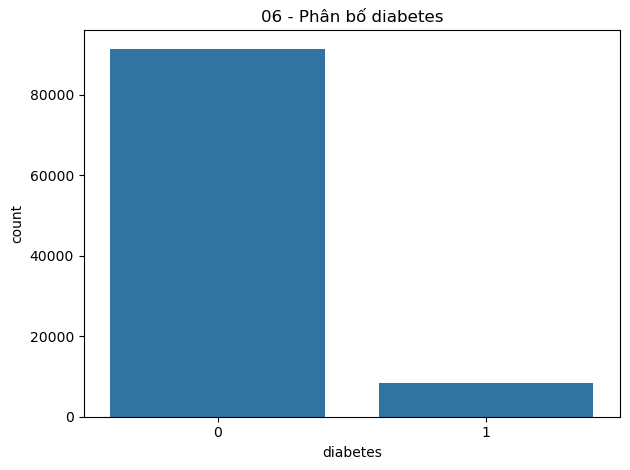

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'diabetes.csv'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
RANDOM_STATE = 24

df = pd.read_csv(DATA)
print('Shape ban đầu:', df.shape)
print('Số dòng trùng lặp:', df.duplicated().sum())
print('Missing values:')
print(df.isna().sum())
print('Phân bố target:')
print(df['diabetes'].value_counts(normalize=True).sort_index())
sns.countplot(data=df, x='diabetes')
plt.title('06 - Phân bố diabetes')
plt.tight_layout()
plt.savefig(FIGURES / '06_diabetes_target_distribution.png', dpi=150)
plt.show()

## 2. Tiền xử lý và lấy mẫu phân tầng

Theo phần ghi đè, không thay thế các giá trị 0. Loại dòng trùng lặp trước khi lấy mẫu; mẫu 10.000 dòng được lấy phân tầng theo target để GridSearchCV chạy trong thời gian hợp lý.

In [2]:
df = df.drop_duplicates().reset_index(drop=True)
sample_df, _ = train_test_split(df, train_size=10000, stratify=df['diabetes'], random_state=RANDOM_STATE)
X = sample_df.drop(columns='diabetes')
y = sample_df['diabetes']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

categorical_features = ['gender', 'smoking_history']
numeric_features = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'hypertension', 'heart_disease']
preprocessor = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('numeric', StandardScaler(), numeric_features),
])
pipeline = Pipeline([('preprocessor', preprocessor), ('svc', SVC(probability=True, random_state=RANDOM_STATE))])
param_grid = {
    'svc__C': [0.1, 1, 10],
    'svc__gamma': ['scale', 0.01],
    'svc__kernel': ['linear', 'rbf'],
    'svc__class_weight': [None, 'balanced'],
}
search = GridSearchCV(pipeline, param_grid, scoring='roc_auc', cv=3, n_jobs=-1, error_score=np.nan, return_train_score=True)
search.fit(X_train, y_train)
print('Kích thước mẫu:', sample_df.shape)
print('Best params:', search.best_params_)
print('Best CV ROC AUC:', search.best_score_)

Kích thước mẫu: (10000, 9)
Best params: {'svc__C': 0.1, 'svc__class_weight': 'balanced', 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Best CV ROC AUC: 0.9632038158819536


## 3. Đánh giá

accuracy     0.886000
precision    0.429730
recall       0.903409
f1           0.582418
roc_auc      0.962227
dtype: float64
              precision    recall  f1-score   support

           0       0.99      0.88      0.93      1824
           1       0.43      0.90      0.58       176

    accuracy                           0.89      2000
   macro avg       0.71      0.89      0.76      2000
weighted avg       0.94      0.89      0.90      2000



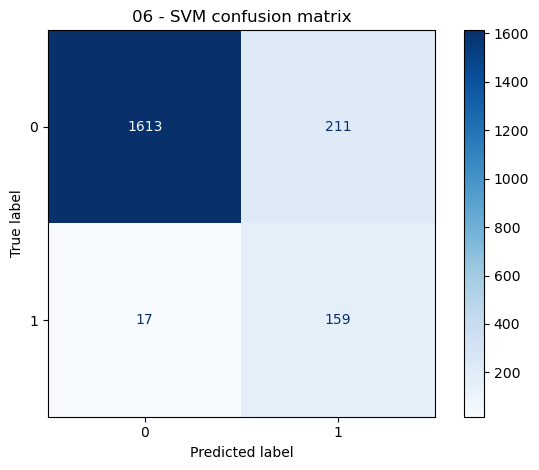

Đã cập nhật results_summary.csv


In [3]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]
metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred, zero_division=0),
    'recall': recall_score(y_test, y_pred, zero_division=0),
    'f1': f1_score(y_test, y_pred, zero_division=0),
    'roc_auc': roc_auc_score(y_test, y_proba),
}
print(pd.Series(metrics))
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(cmap='Blues', values_format='d')
plt.title('06 - SVM confusion matrix')
plt.tight_layout()
plt.savefig(FIGURES / '06_diabetes_svm_confusion_matrix.png', dpi=150)
plt.show()

summary_path = FIGURES / 'results_summary.csv'
summary = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame(columns=['notebook', 'dataset', 'model', 'best_params', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc'])
summary = summary[summary['notebook'] != '06_diabetes_svm']
summary.loc[len(summary)] = ['06_diabetes_svm', 'diabetes', 'SVM', str(search.best_params_), metrics['accuracy'], metrics['precision'], metrics['recall'], metrics['f1'], metrics['roc_auc']]
summary.to_csv(summary_path, index=False)
print('Đã cập nhật results_summary.csv')

## 4. Nhận xét và bảng tóm tắt

Chọn cấu hình theo ROC AUC trên cross-validation, không dùng test set để tuning. `StandardScaler` chỉ fit trên train thông qua Pipeline; `class_weight='balanced'` được thử vì target mất cân bằng. Việc đánh giá trên mẫu phân tầng 10.000 dòng là giả định theo yêu cầu để giảm chi phí SVM.